C:\Users\user\AppData\Local\Temp\ipykernel_20836\1817874536.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customer_satisfaction = pd.read_sql("""


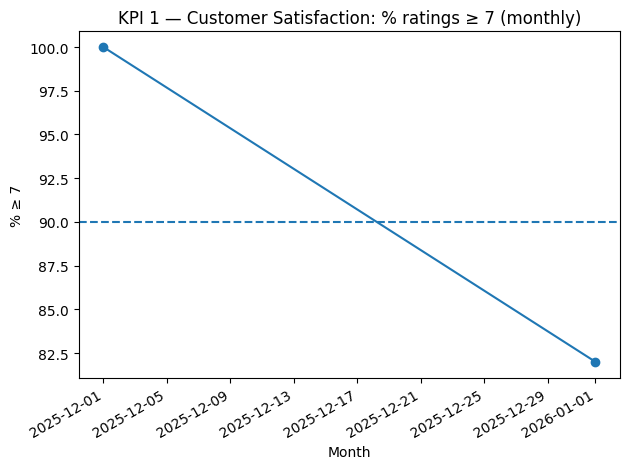

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import pyodbc

SERVER_NAME = r"DESKTOP-6CERR2M\SQLEXPRESS"
DATABASE_NAME = "Stipt"

connection = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={SERVER_NAME};"
    f"DATABASE={DATABASE_NAME};"
    "Trusted_Connection=yes;"
)

# KPI 1 — Customer Satisfaction: % ratings >= 7 (monthly)
customer_satisfaction = pd.read_sql("""
SELECT CustomerSatisfactionID, ClientID, Rating, SubmittedAt
FROM dbo.CustomerSatisfaction
WHERE Rating IS NOT NULL AND SubmittedAt IS NOT NULL;
""", connection)

customer_satisfaction["SubmittedAt"] = pd.to_datetime(customer_satisfaction["SubmittedAt"])
customer_satisfaction["Rating"] = pd.to_numeric(customer_satisfaction["Rating"])
customer_satisfaction = customer_satisfaction.dropna(subset=["SubmittedAt", "Rating"])

customer_satisfaction["Month"] = customer_satisfaction["SubmittedAt"].dt.to_period("M").dt.to_timestamp()
customer_satisfaction["IsRatingSevenOrAbove"] = customer_satisfaction["Rating"] >= 7

customer_satisfaction_kpi = customer_satisfaction.groupby("Month").agg(PercentageSevenOrAbove=("IsRatingSevenOrAbove", "mean"))

customer_satisfaction_kpi["PercentageSevenOrAbove"] = customer_satisfaction_kpi["PercentageSevenOrAbove"] * 100

axis = customer_satisfaction_kpi["PercentageSevenOrAbove"].plot(
    kind="line", marker="o",
    title="KPI 1 — Customer Satisfaction: % ratings ≥ 7 (monthly)"
)
axis.set_ylabel("% ≥ 7")
axis.axhline(90, linestyle="--")  
plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_20836\3777782748.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  employee_satisfaction = pd.read_sql("""
C:\Users\user\AppData\Local\Temp\ipykernel_20836\3777782748.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  employees = pd.read_sql("""


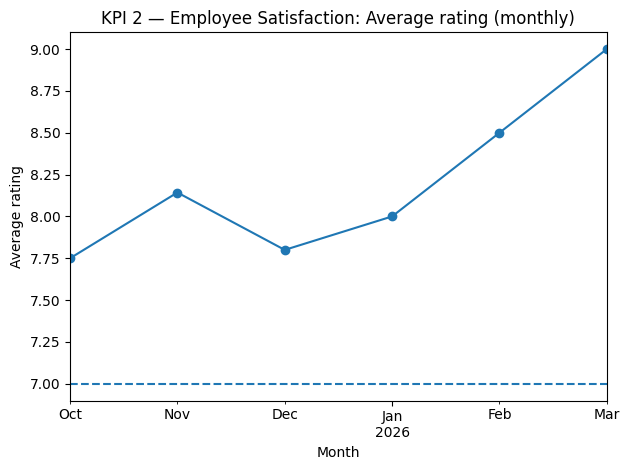

<Figure size 640x480 with 0 Axes>

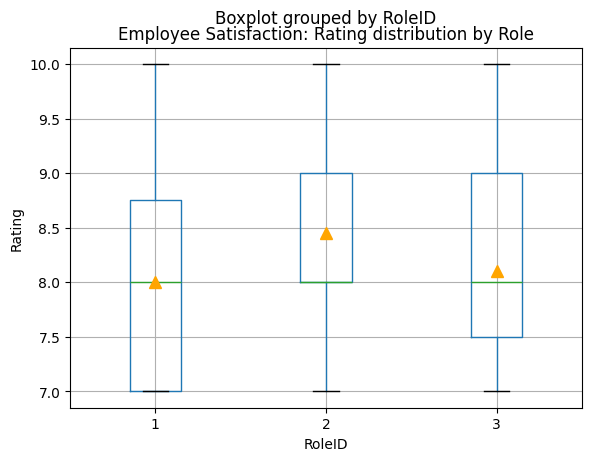

In [3]:
# KPI 2 — Employee Satisfaction: average rating (monthly)

#Graph 1
employee_satisfaction = pd.read_sql("""
SELECT EmployeeSatisfactionID, EmployeeID, Rating, SubmittedAt
FROM dbo.EmployeeSatisfaction
WHERE Rating IS NOT NULL AND SubmittedAt IS NOT NULL;
""", connection)

employees = pd.read_sql("""
SELECT EmployeeID, RoleID, FirstName, LastName
FROM dbo.Employee;
""", connection)

employee_satisfaction["SubmittedAt"] = pd.to_datetime(employee_satisfaction["SubmittedAt"])
employee_satisfaction["Rating"] = pd.to_numeric(employee_satisfaction["Rating"])
employee_satisfaction = employee_satisfaction.dropna(subset=["SubmittedAt", "Rating"])

employee_satisfaction_full = employee_satisfaction.merge(employees, on="EmployeeID", how="left")
employee_satisfaction_full["Month"] = employee_satisfaction_full["SubmittedAt"].dt.to_period("M").dt.to_timestamp()

employee_satisfaction_kpi = employee_satisfaction_full.groupby("Month").agg(AverageRating=("Rating", "mean"))

axis = employee_satisfaction_kpi["AverageRating"].plot(
    kind="line", 
    marker="o",
    title="KPI 2 — Employee Satisfaction: Average rating (monthly)")

axis.set_ylabel("Average rating")
axis.axhline(7, linestyle="--")  # target 7
plt.tight_layout()
plt.show()

#Graph 2
plt.figure()

employee_satisfaction_full.boxplot(
    column="Rating",
    by="RoleID",
    showmeans=True,
    meanprops={
        "marker": "^",
        "markerfacecolor": "orange",
        "markeredgecolor": "orange",
        "markersize": 8
    }
)

plt.title("Employee Satisfaction: Rating distribution by Role")
plt.xlabel("RoleID")
plt.ylabel("Rating")
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_20836\1230434478.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  complaints = pd.read_sql("""


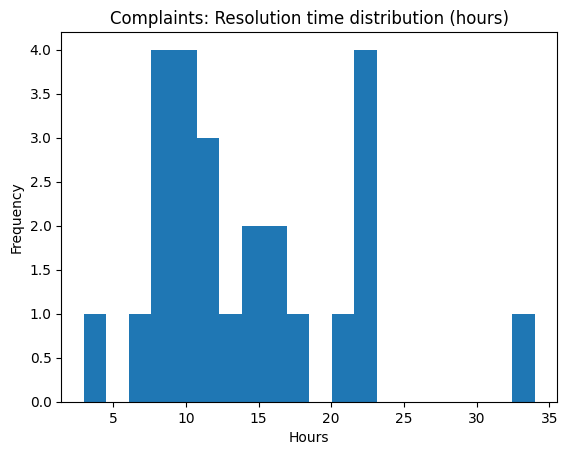

In [4]:

# KPI 3 — Complaints: resolution time histogram (hours)

complaints = pd.read_sql("""
SELECT ComplaintID, CreatedAt, CompletedAt, Status, SiteID, AssignedEmployeeID
FROM dbo.Complaint
WHERE CreatedAt IS NOT NULL;
""", connection)

complaints["CreatedAt"] = pd.to_datetime(complaints["CreatedAt"])
complaints["CompletedAt"] = pd.to_datetime(complaints["CompletedAt"])
complaints = complaints.dropna(subset=["CreatedAt"])

resolved_complaints = complaints.dropna(subset=["CompletedAt"]).copy()
resolved_complaints["ResolutionHours"] = (resolved_complaints["CompletedAt"] - resolved_complaints["CreatedAt"]).dt.total_seconds() / 3600

resolved_complaints = resolved_complaints.dropna(subset=["ResolutionHours"])
resolved_complaints = resolved_complaints[resolved_complaints["ResolutionHours"] >= 0]

axis = resolved_complaints["ResolutionHours"].plot(
    kind="hist",
    bins=20,
    title="Complaints: Resolution time distribution (hours)"
)
axis.set_xlabel("Hours")
plt.show()